# Khảo sát hai dataset cho đồ án HairCare Insight

Notebook này đánh giá dữ liệu hiện có theo đúng phạm vi đồ án:

- **Website kinh doanh:** tập trung vào catalog haircare, giao dịch và trải nghiệm mua hàng của khách. Dữ liệu sản phẩm trong notebook chỉ giúp khảo sát/seed catalog sau khi nhóm kiểm tra và biên tập.
- **Machine Learning:** tập trung riêng vào dự báo số lượng/doanh thu để hỗ trợ Admin. Nếu đổi tên SKU của một dataset bán lẻ tổng quát thành sản phẩm haircare, đây là **dữ liệu mô phỏng**, không phải bằng chứng về nhu cầu haircare thực tế.

Notebook đọc dữ liệu gốc ở chế độ chỉ đọc, không sửa hai dataset.

## 1. Cách chạy và câu hỏi khảo sát

Đặt notebook tại thư mục gốc project như hiện tại rồi chạy lần lượt từ trên xuống. Cần `pandas`, `openpyxl` và `matplotlib`.

Hai file được khảo sát:

1. `ecomcosmetic/E-commerce  cosmetic dataset.csv`
2. `online+retail+ii (1)/online_retail_II.xlsx`

Các câu hỏi chính: dữ liệu nào có catalog haircare, dữ liệu nào có lịch sử giao dịch để dự báo, những trường nào còn thiếu cho bài toán nhập hàng, và đổi tên sản phẩm thế nào để giữ được tính nhất quán của dữ liệu mô phỏng.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    candidates = [current, *current.parents]
    for candidate in candidates:
        for source_root in [candidate / 'raw', candidate / 'data' / 'ml' / 'raw', candidate]:
            if (source_root / 'ecomcosmetic').is_dir() and (source_root / 'online+retail+ii (1)').is_dir():
                return candidate, source_root
    raise FileNotFoundError('Không tìm thấy hai thư mục dataset raw. Hãy đặt notebook trong project hoặc thư mục con của project.')

ROOT, SOURCE_ROOT = find_project_root()
COSMETIC_PATH = SOURCE_ROOT / 'ecomcosmetic' / 'E-commerce  cosmetic dataset.csv'
RETAIL_PATH = SOURCE_ROOT / 'online+retail+ii (1)' / 'online_retail_II.xlsx'
print('Project root:', ROOT)
print('Cosmetic CSV:', COSMETIC_PATH.exists(), f'({COSMETIC_PATH.stat().st_size / 1_000_000:.1f} MB)')
print('Retail workbook:', RETAIL_PATH.exists(), f'({RETAIL_PATH.stat().st_size / 1_000_000:.1f} MB)')

Project root: E:\UEL\WebML_Project\data
Cosmetic CSV: True (7.6 MB)
Retail workbook: True (45.6 MB)


## 2. Dataset mỹ phẩm: có thể dùng làm catalog haircare, không phải dữ liệu bán hàng

File CSV có thông tin tên sản phẩm, website, quốc gia, category/subcategory, thương hiệu, giá, thành phần, kích cỡ và rating. File dùng encoding `cp1252`; notebook nạp bằng encoding đó để tránh lỗi giải mã.

In [2]:
cosmetics = pd.read_csv(COSMETIC_PATH, encoding='cp1252', low_memory=False)
required_cosmetic_columns = {'product_name', 'website', 'country', 'category', 'subcategory', 'price', 'brand'}
missing_columns = required_cosmetic_columns - set(cosmetics.columns)
if missing_columns:
    raise ValueError(f'Thiếu các cột dự kiến trong CSV: {sorted(missing_columns)}')

cosmetic_profile = pd.DataFrame({
    'Chỉ số': ['Số dòng', 'Số cột', 'Tên sản phẩm duy nhất', 'Thiếu giá', 'Thiếu thành phần', 'Thiếu rating'],
    'Giá trị': [
        len(cosmetics), len(cosmetics.columns), cosmetics['product_name'].nunique(),
        int(cosmetics['price'].isna().sum()),
        int(cosmetics['ingredients'].isna().sum()) if 'ingredients' in cosmetics else None,
        int(cosmetics['rating'].isna().sum()) if 'rating' in cosmetics else None,
    ],
})
display(cosmetic_profile)
display(cosmetics['category'].value_counts().rename_axis('category').to_frame('số sản phẩm'))

,Chỉ số,Giá trị
0,Số dòng,12615
1,Số cột,15
2,Tên sản phẩm duy nhất,11341
3,Thiếu giá,317
4,Thiếu thành phần,6015
5,Thiếu rating,2067


,số sản phẩm
category,
body,2555
lips,2478
eyes,2425
skincare,2077
face,1579
hair,1501


Sản phẩm category='hair': 1,501 / 12,615 (11.9%)


,số sản phẩm
mapped_category,
shampoo,517
hairmask,407
treatment,398
dry shampoo,88
conditioner,61
hairstyling,30


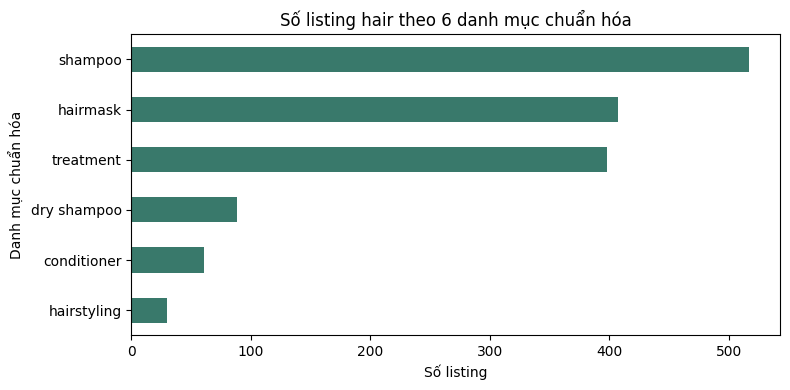

,product_name,brand,subcategory,mapped_category,price,size,rating
4981,"TIG Hair Fall Rescue Shampoo 200 , For Damaged...",TIG,shampoo,shampoo,712.0,NaN,NaN
4982,7th Heaven Manuka Honey Hair Mask and Root Res...,7th Heaven,hairmask,hairmask,297.0,25,NaN
4983,Aegte Keralution Hair Mask ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï...,Aegte,hairmask,hairmask,420.0,100,NaN
4984,AlfaParf Semi Di Lino Moisture Nutritive Leave...,AlfaParf,conditioner,conditioner,1450.0,NaN,4.5
4985,Arata Anti-Dandruff Hair And Scalp Mask (100 G...,Arata,hairmask,hairmask,33500.0,100,NaN
4986,Argatin Botox With Keratin Damage Repair Treat...,ARGATIN,hairmask,hairmask,159.0,200,NaN
4987,Argatin Botox With Keratin Damage Repair Treat...,ARGATIN,hairmask,hairmask,351.0,200,NaN
4988,Argatin Keratin O+ Smooth Repair Hair Mask 250...,ARGATIN,hairmask,hairmask,468.0,250,NaN
4989,Artnaturals Argan Oil Hair Mask Deep Condition...,Artnaturals,hairmask,hairmask,266.0,226,NaN
4990,Ashba Botanics Deep Treatment Hair Masque | Ha...,Ashba Botanics,hairmask,hairmask,870.0,237,NaN


In [3]:
hair_products = cosmetics[cosmetics['category'].astype('string').str.strip().str.casefold().eq('hair')].copy()
hair_share = len(hair_products) / len(cosmetics) if len(cosmetics) else 0
print(f"Sản phẩm category='hair': {len(hair_products):,} / {len(cosmetics):,} ({hair_share:.1%})")
hair_products['subcategory_normalized'] = hair_products['subcategory'].astype('string').str.strip().str.casefold().str.replace(r'\s+', ' ', regex=True)
category_mapping = {
    'shampoo': 'shampoo', 'hairmask': 'hairmask', 'oil': 'treatment',
    'serum': 'treatment', 'treatment / oil': 'treatment',
    'dry shampoo': 'dry shampoo', 'conditioner': 'conditioner',
    'hairstyling': 'hairstyling',
}
hair_products['mapped_category'] = hair_products['subcategory_normalized'].map(category_mapping)
display(hair_products['mapped_category'].value_counts(dropna=False).rename_axis('mapped_category').to_frame('số sản phẩm'))

hair_category_counts = hair_products['mapped_category'].value_counts().sort_values(ascending=True)
hair_category_counts.plot(kind='barh', figsize=(8, 4), color='#39796b')
plt.title('Số listing hair theo 6 danh mục chuẩn hóa')
plt.xlabel('Số listing')
plt.ylabel('Danh mục chuẩn hóa')
plt.tight_layout()
plt.show()

display(hair_products[['product_name', 'brand', 'subcategory', 'mapped_category', 'price', 'size', 'rating']].head(12))

### Nhận xét sơ bộ về CSV

- Có listing haircare thực tế và các trường hữu ích để nhóm **tham khảo/biên tập catalog web**; category `hair` không đồng nghĩa mọi dòng đã có nhãn sản phẩm chuẩn.
- Taxonomy demo hiện gồm 6 danh mục: shampoo, hairmask, treatment, dry shampoo, conditioner và hairstyling. Subcategory gốc `oil` và `serum` được gom vào `treatment`; cột subcategory nguồn vẫn được giữ nguyên để truy vết.
- Đây là listing sản phẩm, không có ngày bán, số lượng bán, đơn hàng hay tồn kho. Vì vậy **không dùng CSV này để huấn luyện mô hình dự báo doanh thu/nhu cầu**.
- Giá đến từ nhiều website/quốc gia; cần kiểm tra tiền tệ, chuẩn hóa giá và xác minh nguồn trước khi đưa lên website. Tên/ảnh/thành phần/rating cũng cần kiểm duyệt và ghi nguồn theo yêu cầu môn học.

## 3. Online Retail II: có lịch sử giao dịch, nhưng không phải ngành haircare

Workbook có hai sheet theo giai đoạn. Các cột gồm Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID và Country. Notebook đọc từng sheet, chỉ giữ các cột cần thiết, loại các dòng hủy/hoàn hoặc dữ liệu không hợp lệ trước khi tổng hợp bán hàng.

Hai sheet có một số Invoice trùng nhau ở vùng ngày giao nhau. Vì các dòng hóa đơn trùng đã được kiểm tra giống nhau, notebook giữ bản ở sheet đầu tiên và bỏ invoice trùng ở sheet sau để tránh đếm doanh thu hai lần.

In [4]:
excel_file = pd.ExcelFile(RETAIL_PATH, engine='openpyxl')
print('Sheets:', excel_file.sheet_names)

use_columns = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
seen_invoices = set()
retail_quality_rows = []
daily_parts = []
monthly_parts = []
sku_parts = []

for sheet_name in excel_file.sheet_names:
    raw = pd.read_excel(excel_file, sheet_name=sheet_name, usecols=use_columns, engine='openpyxl')
    raw['Invoice'] = raw['Invoice'].astype('string').str.strip()
    raw['StockCode'] = raw['StockCode'].astype('string').str.strip()
    raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
    raw['Quantity'] = pd.to_numeric(raw['Quantity'], errors='coerce')
    raw['Price'] = pd.to_numeric(raw['Price'], errors='coerce')

    duplicate_invoice_mask = raw['Invoice'].isin(seen_invoices)
    duplicate_invoice_count = int(raw.loc[duplicate_invoice_mask, 'Invoice'].nunique())
    raw = raw.loc[~duplicate_invoice_mask].copy()
    seen_invoices.update(raw['Invoice'].dropna().unique().tolist())

    is_cancelled = raw['Invoice'].str.upper().str.startswith('C', na=False)
    is_valid_sale = (
        ~is_cancelled & raw['Quantity'].gt(0) & raw['Price'].gt(0)
        & raw['InvoiceDate'].notna() & raw['StockCode'].notna()
    )
    sales = raw.loc[is_valid_sale, ['Invoice', 'StockCode', 'Description', 'InvoiceDate', 'Quantity', 'Price', 'Country']].copy()
    sales['Revenue'] = sales['Quantity'] * sales['Price']
    sales['Date'] = sales['InvoiceDate'].dt.floor('D')
    sales['Month'] = sales['InvoiceDate'].dt.to_period('M').dt.to_timestamp()

    retail_quality_rows.append({
        'Sheet': sheet_name,
        'Dòng gốc': len(raw) + int(duplicate_invoice_mask.sum()),
        'Invoice trùng bỏ khỏi sheet này': duplicate_invoice_count,
        'Invoice duy nhất sau xử lý': int(raw['Invoice'].nunique()),
        'Dòng bị hủy': int(is_cancelled.sum()),
        'Dòng Quantity âm': int(raw['Quantity'].lt(0).sum()),
        'Dòng bán hợp lệ': len(sales),
        'SKU duy nhất bán hợp lệ': int(sales['StockCode'].nunique()),
        'Thiếu Customer ID': int(raw['Customer ID'].isna().sum()),
        'Ngày đầu': sales['InvoiceDate'].min(),
        'Ngày cuối': sales['InvoiceDate'].max(),
    })

    daily_parts.append(sales.groupby(['Date', 'StockCode'], as_index=False).agg(
        Quantity=('Quantity', 'sum'), Revenue=('Revenue', 'sum')
    ))
    monthly_parts.append(sales.groupby('Month', as_index=False).agg(
        Quantity=('Quantity', 'sum'), Revenue=('Revenue', 'sum')
    ))
    sku_parts.append(sales.groupby('StockCode', as_index=False).agg(
        Description=('Description', 'first'), Quantity=('Quantity', 'sum'),
        Revenue=('Revenue', 'sum'), InvoiceCount=('Invoice', 'nunique')
    ))
    del raw, sales

retail_quality = pd.DataFrame(retail_quality_rows)
display(retail_quality)

Sheets: ['Year 2009-2010', 'Year 2010-2011']


,Sheet,Dòng gốc,Invoice trùng bỏ khỏi sheet này,Invoice duy nhất sau xử lý,Dòng bị hủy,Dòng Quantity âm,Dòng bán hợp lệ,SKU duy nhất bán hợp lệ,Thiếu Customer ID,Ngày đầu,Ngày cuối
0,Year 2009-2010,525461,0,28816,10206,12326,511565,4250,107927,2009-12-01 07:45:00,2010-12-09 20:01:00
1,Year 2010-2011,541910,1088,24812,8959,10231,508089,3879,127360,2010-12-10 09:33:00,2011-12-09 12:50:00


Dòng SKU-ngày sau làm sạch: 532,838
SKU có giao dịch hợp lệ: 4,916


,StockCode,Description,Quantity,Revenue,InvoiceCount
3541,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106379,24507.53,1019
4272,85099B,JUMBO BAG RED WHITE SPOTTY,96931,180888.03,3989
615,21212,PACK OF 72 RETRO SPOT CAKE CASES,94972,51873.55,3118
4300,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94323,258065.91,5365
1433,22197,"POPCORN HOLDER , SMALL",88537,79552.50,2322
2798,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3990,84879,ASSORTED COLOUR BIRD ORNAMENT,80293,129681.08,2807
2353,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
114,17003,BROCADE RING PURSE,70405,14776.86,456
1246,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56230,28159.08,1993


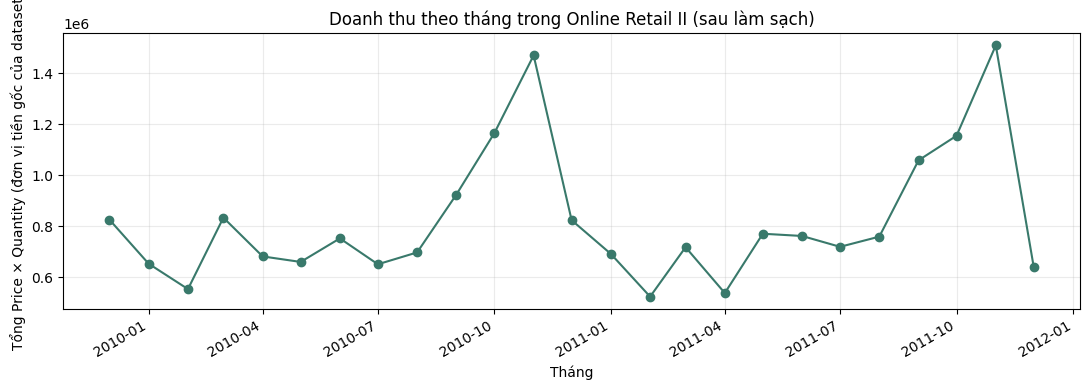

In [5]:
daily_sales = pd.concat(daily_parts, ignore_index=True).groupby(['Date', 'StockCode'], as_index=False).agg(
    Quantity=('Quantity', 'sum'), Revenue=('Revenue', 'sum')
)
monthly_sales = pd.concat(monthly_parts, ignore_index=True).groupby('Month', as_index=False).agg(
    Quantity=('Quantity', 'sum'), Revenue=('Revenue', 'sum')
).sort_values('Month')
sku_sales = pd.concat(sku_parts, ignore_index=True).groupby('StockCode', as_index=False).agg(
    Description=('Description', 'first'), Quantity=('Quantity', 'sum'),
    Revenue=('Revenue', 'sum'), InvoiceCount=('InvoiceCount', 'sum')
).sort_values('Quantity', ascending=False)

print(f"Dòng SKU-ngày sau làm sạch: {len(daily_sales):,}")
print(f"SKU có giao dịch hợp lệ: {daily_sales['StockCode'].nunique():,}")
display(sku_sales.head(12))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_sales['Month'], monthly_sales['Revenue'], marker='o', linewidth=1.5, color='#39796b')
ax.set_title('Doanh thu theo tháng trong Online Retail II (sau làm sạch)')
ax.set_xlabel('Tháng')
ax.set_ylabel('Tổng Price × Quantity (đơn vị tiền gốc của dataset)')
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Đánh giá cho bài toán ML

**Điểm phù hợp:** có thời điểm giao dịch, StockCode, số lượng và đơn giá nên có thể tạo chuỗi bán theo ngày/tháng; thử dự báo Quantity hoặc Revenue theo thời gian, chia train/test theo thời gian và tính MAE/RMSE/MAPE. Cần lọc invoice hủy, quantity âm (hoàn/điều chỉnh), price không hợp lệ và tránh rò rỉ dữ liệu tương lai.

**Giới hạn quan trọng:** dữ liệu này là giao dịch bán lẻ nhiều mặt hàng (phần lớn đồ gia dụng/quà tặng), không phải haircare; không có cột tồn kho, lead time, chương trình khuyến mãi hay danh mục haircare. Giá tiền cũng thuộc ngữ cảnh nguồn, không tự động là VNĐ. Vì vậy mô hình trên dữ liệu này chỉ minh họa quy trình, không chứng minh mô hình dự báo đúng nhu cầu sản phẩm chăm sóc tóc.

Nếu dùng để demo HairCare Insight, hãy tạo mapping cố định `StockCode → mã/tên sản phẩm haircare giả lập` và ghi rõ mapping chỉ đổi nhãn. Không gán danh mục theo Description cũ, không thay đổi StockCode qua các ngày, và không tuyên bố doanh thu/danh mục tổng hợp là dữ liệu haircare thực. Tồn kho/lead time cần là dữ liệu cấu hình mô phỏng riêng hoặc lấy từ đơn hàng phát sinh trên website.

In [6]:
demo_name_templates = pd.DataFrame([
    ('Dầu gội', 'HC-SH-001', 'Dầu gội cân bằng da đầu – Citrus Balance Shampoo'),
    ('Dầu xả', 'HC-CO-001', 'Dầu xả phục hồi độ ẩm – Moisture Repair Conditioner'),
    ('Ủ tóc', 'HC-MA-001', 'Mặt nạ ủ tóc phục hồi – Deep Repair Hair Mask'),
    ('Dưỡng tóc', 'HC-TR-001', 'Tinh chất dưỡng ngọn tóc – Smooth Ends Hair Serum'),
    ('Chăm sóc da đầu', 'HC-SC-001', 'Tinh chất làm dịu da đầu – Calm Scalp Tonic'),
    ('Chống rụng tóc', 'HC-FA-001', 'Dầu dưỡng tóc chắc khỏe – Root Strength Hair Oil'),
    ('Bảo vệ tóc', 'HC-PR-001', 'Xịt bảo vệ tóc khỏi nhiệt – Heat Shield Hair Spray'),
    ('Tạo kiểu tóc', 'HC-ST-001', 'Kem tạo kiểu giữ nếp linh hoạt – Flexible Hold Styling Cream'),
], columns=['Danh mục haircare demo', 'Mã sản phẩm demo', 'Tên sản phẩm giả lập'])
display(demo_name_templates)

top_skus = sku_sales.head(len(demo_name_templates)).reset_index(drop=True)
rename_preview = pd.concat([
    top_skus[['StockCode', 'Description', 'Quantity']].rename(columns={
        'StockCode': 'StockCode nguồn', 'Description': 'Tên nguồn (không phải haircare)', 'Quantity': 'Tổng Quantity lịch sử'
    }),
    demo_name_templates.reset_index(drop=True),
], axis=1)
display(rename_preview)
print('Lưu ý: preview trên ghép SKU bán nhiều với tên mẫu theo thứ tự để minh họa kỹ thuật đổi nhãn; đây KHÔNG phải phân loại sản phẩm có căn cứ.')

,Danh mục haircare demo,Mã sản phẩm demo,Tên sản phẩm giả lập
0,Dầu gội,HC-SH-001,Dầu gội cân bằng da đầu – Citrus Balance Shampoo
1,Dầu xả,HC-CO-001,Dầu xả phục hồi độ ẩm – Moisture Repair Condit...
2,Ủ tóc,HC-MA-001,Mặt nạ ủ tóc phục hồi – Deep Repair Hair Mask
3,Dưỡng tóc,HC-TR-001,Tinh chất dưỡng ngọn tóc – Smooth Ends Hair Serum
4,Chăm sóc da đầu,HC-SC-001,Tinh chất làm dịu da đầu – Calm Scalp Tonic
5,Chống rụng tóc,HC-FA-001,Dầu dưỡng tóc chắc khỏe – Root Strength Hair Oil
6,Bảo vệ tóc,HC-PR-001,Xịt bảo vệ tóc khỏi nhiệt – Heat Shield Hair S...
7,Tạo kiểu tóc,HC-ST-001,Kem tạo kiểu giữ nếp linh hoạt – Flexible Hold...


,StockCode nguồn,Tên nguồn (không phải haircare),Tổng Quantity lịch sử,Danh mục haircare demo,Mã sản phẩm demo,Tên sản phẩm giả lập
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106379,Dầu gội,HC-SH-001,Dầu gội cân bằng da đầu – Citrus Balance Shampoo
1,85099B,JUMBO BAG RED WHITE SPOTTY,96931,Dầu xả,HC-CO-001,Dầu xả phục hồi độ ẩm – Moisture Repair Condit...
2,21212,PACK OF 72 RETRO SPOT CAKE CASES,94972,Ủ tóc,HC-MA-001,Mặt nạ ủ tóc phục hồi – Deep Repair Hair Mask
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94323,Dưỡng tóc,HC-TR-001,Tinh chất dưỡng ngọn tóc – Smooth Ends Hair Serum
4,22197,"POPCORN HOLDER , SMALL",88537,Chăm sóc da đầu,HC-SC-001,Tinh chất làm dịu da đầu – Calm Scalp Tonic
5,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,Chống rụng tóc,HC-FA-001,Dầu dưỡng tóc chắc khỏe – Root Strength Hair Oil
6,84879,ASSORTED COLOUR BIRD ORNAMENT,80293,Bảo vệ tóc,HC-PR-001,Xịt bảo vệ tóc khỏi nhiệt – Heat Shield Hair S...
7,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,Tạo kiểu tóc,HC-ST-001,Kem tạo kiểu giữ nếp linh hoạt – Flexible Hold...


Lưu ý: preview trên ghép SKU bán nhiều với tên mẫu theo thứ tự để minh họa kỹ thuật đổi nhãn; đây KHÔNG phải phân loại sản phẩm có căn cứ.


## 4. Kết luận và khuyến nghị cho nhóm

| Dataset | Website haircare | ML dự báo bán hàng | Kết luận |
|---|---|---|---|
| E-commerce cosmetic CSV | **Có điều kiện:** có 1.501 listing category `hair`; cần lọc/kiểm duyệt, chuẩn hóa giá và gán lại 8 danh mục nghiệp vụ | **Không phù hợp:** không có thời gian, quantity bán, đơn hàng hoặc tồn kho | Dùng làm nguồn tham khảo catalog sau biên tập, không dùng để đánh giá mô hình |
| Online Retail II XLSX | **Không phù hợp làm catalog:** mô tả là mặt hàng bán lẻ không chuyên haircare | **Có điều kiện:** có giao dịch theo SKU/ngày, Quantity và Price; phù hợp thực hành pipeline time-series nhưng domain khác và thiếu tồn kho/khuyến mãi | Tốt hơn trong hai bộ để minh họa quy trình ML bằng dữ liệu mô phỏng; phải ghi rõ hạn chế |

### Đề xuất triển khai mô phỏng

1. Giữ nguyên file nguồn; tạo một bảng mapping riêng theo `StockCode` và gán một tên giả lập cố định cho mỗi SKU. Dùng các tên mẫu ở trên làm catalog minh họa, nhưng rà soát mapping thủ công trước khi gắn nhãn category.
2. Với từng SKU, tổng hợp `Quantity` và `Revenue = Quantity × Price` theo ngày/tuần; loại giao dịch hủy/hoàn theo quy tắc đã công bố. Chia tập train/test theo thời gian, so sánh baseline với Linear Regression/Random Forest và báo MAE, RMSE, MAPE.
3. Trình bày rõ kết quả là **mô phỏng dựa trên mẫu hình bán lẻ tổng quát**, không suy rộng thành nhu cầu thật của ngành haircare. MAPE cần xử lý cẩn thận khi actual bằng 0; nên báo thêm MAE/RMSE và cách tính.
4. Bảng gợi ý nhập hàng cần có tham số tồn kho hiện tại, lead time, chu kỳ nhập và safety stock riêng. Công thức nghiệp vụ trong tài liệu nhóm: `max(0, nhu cầu dự báo trong (lead time + chu kỳ nhập) + tồn an toàn - tồn kho hiện tại)`. Online Retail II không cung cấp sẵn các trường tồn kho này.
5. Khi website có đơn haircare thật, lưu SKU, ngày, quantity, giá snapshot, khuyến mãi và trạng thái đơn. Chỉ đưa đơn hợp lệ vào huấn luyện theo business rule; có thể dùng dữ liệu thật của web làm nguồn phù hợp hơn và giữ dataset mô phỏng làm dữ liệu minh họa.

**Kết luận ngắn:** hai dataset bổ trợ hai phần khác nhau. CSV có thể hỗ trợ xây dựng danh mục sản phẩm haircare sau khi làm sạch; Online Retail II có cấu trúc lịch sử bán hàng để thử nghiệm ML nhưng không phải dữ liệu haircare. Không dataset nào hiện có một mình vừa đáp ứng catalog haircare vừa hỗ trợ dự báo nhu cầu haircare thực tế.